# Data Analysis Notebook

## Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import sys

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # type: ignore

## Import Paths

In [5]:
from pathlib import Path
from utils.path_loader import load_paths
paths = load_paths()

PROJECT_ROOT = paths["project_root"]
#print(PROJECT_ROOT)



## Import Functions

In [6]:
from analysis.train_data.yolo.cv_yolo_full_eda import run_full_cv_yolo_eda


In [7]:
# import importlib
# import analysis.train_data.yolo.cv_yolo_full_eda as eda

# importlib.reload(eda)


In [8]:
# df, summary_df, eda_text = run_full_cv_yolo_eda(save_csv=True)
# df


## Load the Data

In [9]:
yolo_train_data_csv_path = PROJECT_ROOT /"src"/ "analysis"/"train_data"/"yolo"/"cv_yolo_full_analysis.csv"

df_complete = pd.read_csv(yolo_train_data_csv_path)
print("Head of the dataset:")
print(df_complete.head())
print("\nColumns of the dataset:")
print(df_complete.columns)

Head of the dataset:
                                           filename  \
0   02657761cacdda99-scrapped_resumes-architect.jpg   
1   02657761cacdda99-scrapped_resumes-architect.jpg   
2  0287439839da10d2-scrapped_resumes-accountant.jpg   
3  0287439839da10d2-scrapped_resumes-accountant.jpg   
4  028cd00be9bb156d-scrapped_resumes-accountant.jpg   

                                                path   width  height  \
0  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
1  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
2  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
3  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
4  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   768.0  1087.0   

   num_pixels width_height  aspect_ratio  colorfulness  color_variation  \
0   2965504.0    1448x2048      0.707031     30.761051         0.194928   
1   2965504.0    1448x2048      0.707031     30.761051         0.

## Variáveis
#####  aspect_ratio = width / height:
* < 1 -> imagem mais alta que larga (formato típico de página A4)
* ≈ 0.7 -> muito comum em CVs digitalizados
* > 1 -> imagem horizontal (raro em CVs)

#####  colorfulness (quão “colorida” é a imagem):
* < 10 -> quase preto-e-branco
* 10 – 30 -> documento simples
* > 30 -> cores fortes / gráficos

#####  color_variation (desvio padrão médio dos canais RGB (0–1)):
* < 0.1 -> muito uniforme
* 0.1 – 0.25 -> algumas cores 
* > 0.3 -> muitos cores

##### x_center_mean e y_center_mean são:
A posição média dos objetos(bounding boxes) detetados no CV, em coordenadas normalizadas do formato YOLO. Ex.: y_center = 0.2 -> objeto perto do topo

## 1. Yolo EDA

### 1.1 Explore the Data

#### 1.1.1 Remover casos have_to_remove = True

In [10]:
df_complete = df_complete.drop_duplicates(subset="filename")
df_complete.describe

<bound method NDFrame.describe of                                                filename  \
0       02657761cacdda99-scrapped_resumes-architect.jpg   
2      0287439839da10d2-scrapped_resumes-accountant.jpg   
4      028cd00be9bb156d-scrapped_resumes-accountant.jpg   
6     035a6c9b5ae923b0-scrapped_resumes-agriculture.jpg   
8      0452d98376727179-scrapped_resumes-accountant.jpg   
...                                                 ...   
3491     97_jpg.rf.77c498d3c97ad821d62ab5f1bf7492c7.jpg   
3492     98_jpg.rf.bce63a9765af54345e5f401123cd4058.jpg   
3493     99_jpg.rf.ac43cf7a7db01207af24e74dab6f0440.jpg   
3494              Image_42-bing_images-arts_resumes.jpg   
3495              Image_42-bing_images-arts_resumes.png   

                                                   path   width  height  \
0     C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
2     C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
4     C:\Users\danie\Desktop\lab

In [11]:
df_remove = df_complete[df_complete["have_to_remove"] == True].copy()
df_yolo = df_complete[df_complete["have_to_remove"] == False].copy()
df_yolo = df_yolo.drop_duplicates(subset="filename")


In [12]:
len(df_remove)

116

In [13]:
df_yolo.head()

,filename,path,width,height,num_pixels,width_height,aspect_ratio,colorfulness,color_variation,mean_r,...,has_labels,have_to_remove,number_text_block,number_photo,number_skill_table,x_center_mean,y_center_mean,in_text_photo_dataset,in_skill_table_dataset,has_any_object
0,02657761cacdda99-scrapped_resumes-architect.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,1448.0,2048.0,2965504.0,1448x2048,0.707031,30.761051,0.194928,239.67635,...,True,False,9,1,0,0.316264,0.370093,True,True,True
2,0287439839da10d2-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,600.0,730.0,438000.0,600x730,0.821918,13.419292,0.191884,236.84930,...,True,False,6,0,0,0.434028,0.381507,True,True,True
4,028cd00be9bb156d-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,768.0,1087.0,834816.0,768x1087,0.706532,36.614601,0.177965,242.96956,...,True,False,6,0,9,0.479427,0.483471,True,True,True
6,035a6c9b5ae923b0-scrapped_resumes-agriculture.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,1200.0,1714.0,2056800.0,1200x1714,0.700117,7.853670,0.201864,238.44190,...,True,False,7,1,0,0.385677,0.475022,True,True,True
8,0452d98376727179-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,544.0,769.0,418336.0,544x769,0.707412,39.265636,0.368994,169.45143,...,True,False,7,1,6,0.293658,0.393786,True,True,True


#### 1.1.2 Dataset apenas para cada tipo de deteção:

In [14]:
df_skill_table = df_yolo[df_yolo["in_skill_table_dataset"] == True].copy()

df_text_photo = df_yolo[df_yolo["in_text_photo_dataset"] == True].copy()


#### 1.1.7 Dividing categorical and numerical variables

In [15]:
numeric_cols_yolo = df_yolo.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols_yolo = df_yolo.select_dtypes(include=['object']).columns.tolist()

numeric_cols_yolo, categorical_cols_yolo

(['width',
  'height',
  'num_pixels',
  'aspect_ratio',
  'colorfulness',
  'color_variation',
  'mean_r',
  'mean_g',
  'mean_b',
  'std_r',
  'std_g',
  'std_b',
  'number_text_block',
  'number_photo',
  'number_skill_table',
  'x_center_mean',
  'y_center_mean'],
 ['filename', 'path', 'width_height', 'has_labels'])

### 1.2 Graphics

#### 1.2.1 Graph of the distribution of numerical variables

array([[<Axes: title={'center': 'width'}>,
        <Axes: title={'center': 'height'}>,
        <Axes: title={'center': 'num_pixels'}>,
        <Axes: title={'center': 'aspect_ratio'}>],
       [<Axes: title={'center': 'colorfulness'}>,
        <Axes: title={'center': 'color_variation'}>,
        <Axes: title={'center': 'mean_r'}>,
        <Axes: title={'center': 'mean_g'}>],
       [<Axes: title={'center': 'mean_b'}>,
        <Axes: title={'center': 'std_r'}>,
        <Axes: title={'center': 'std_g'}>,
        <Axes: title={'center': 'std_b'}>],
       [<Axes: title={'center': 'number_text_block'}>,
        <Axes: title={'center': 'number_photo'}>,
        <Axes: title={'center': 'number_skill_table'}>,
        <Axes: title={'center': 'x_center_mean'}>],
       [<Axes: title={'center': 'y_center_mean'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

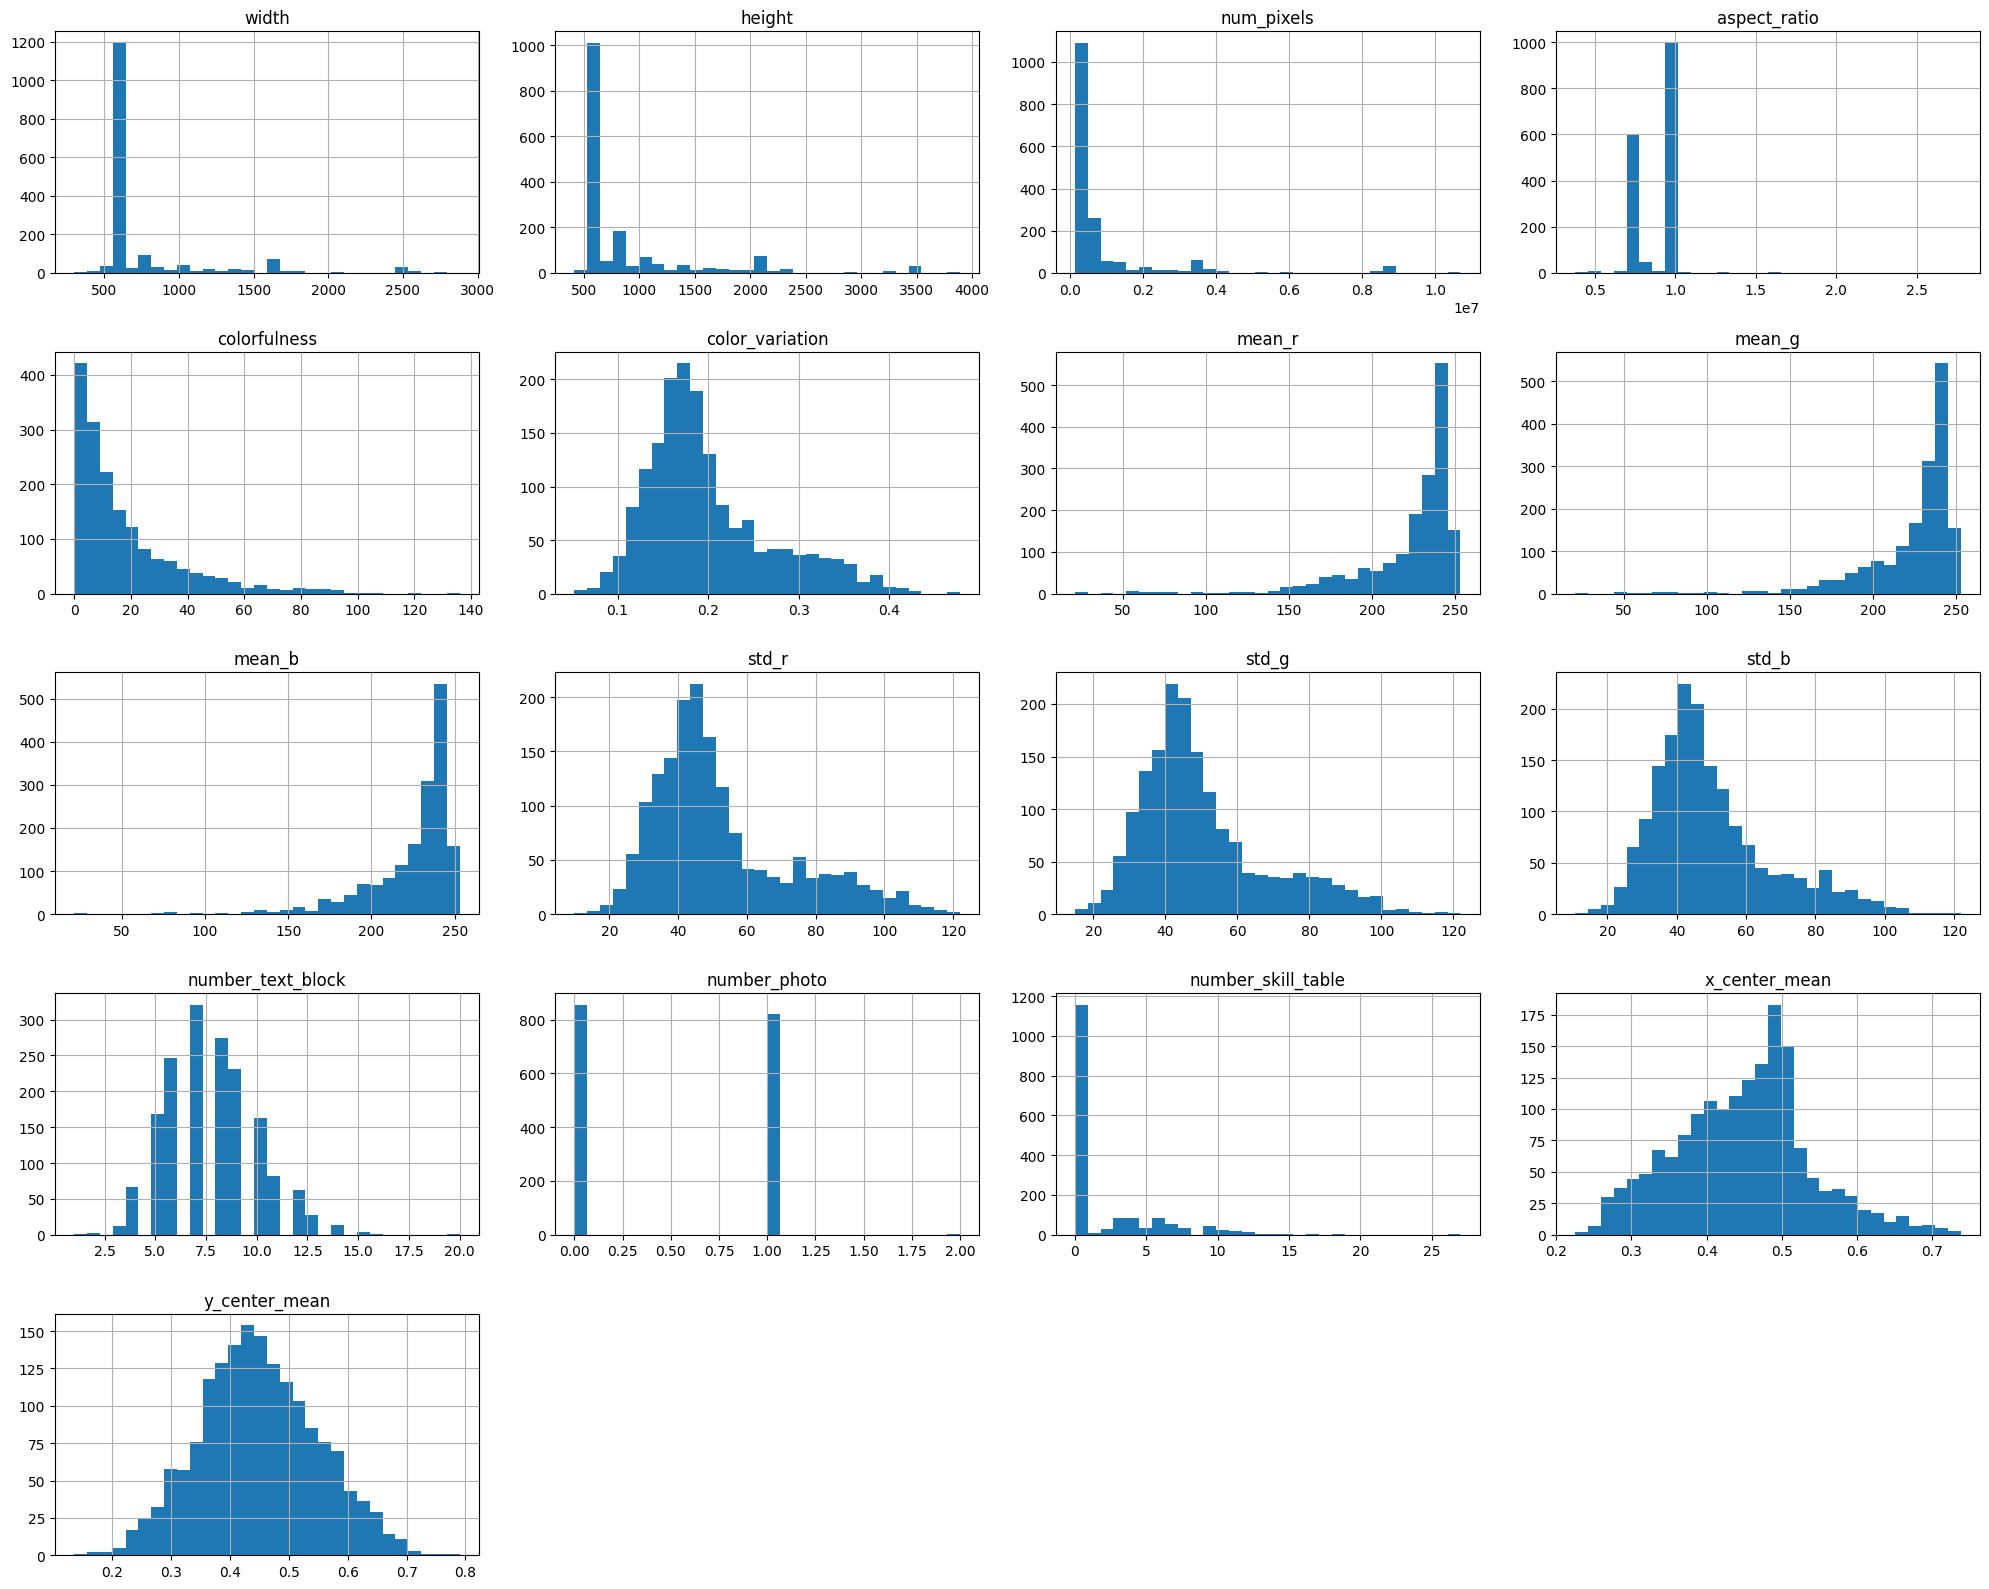

In [16]:
df_yolo[numeric_cols_yolo].hist(figsize=(20,16), bins=30)
plt.tight_layout()
plt.show()

#### 1.2.2 Graphs of the bounding boxes

<Figure size 800x500 with 0 Axes>

<BarContainer object of 3 artists>

Text(0.5, 1.0, 'Total Number of Bounding Boxes per Type in the CV Dataset')

Text(0, 0.5, 'Total Number of Occurrences')

Text(0.5, 0, 'Bounding Box Type')

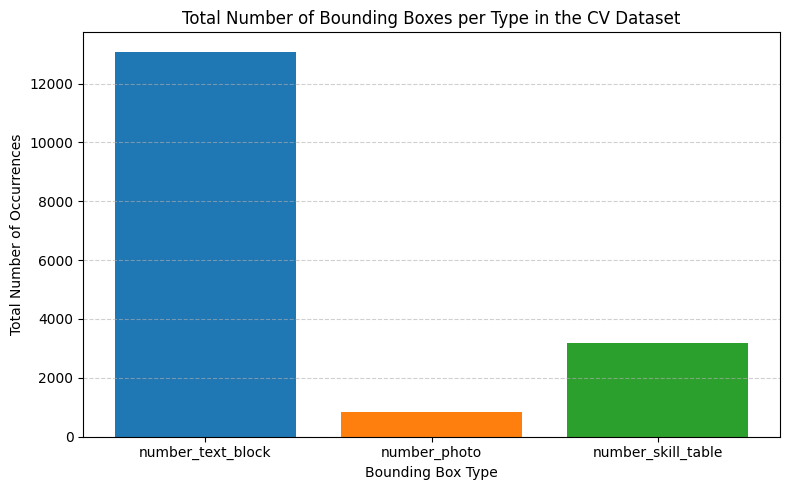

In [17]:
# Select only the desired columns
cols = ["number_text_block", "number_photo", "number_skill_table"]

# Sum the total number of bounding boxes per type
totals = df_yolo[cols].sum()

# Create bar chart with different colors
plt.figure(figsize=(8, 5))
plt.bar(
    totals.index,
    totals.values,
    color=["tab:blue", "tab:orange", "tab:green"]
)

plt.title("Total Number of Bounding Boxes per Type in the CV Dataset")
plt.ylabel("Total Number of Occurrences")
plt.xlabel("Bounding Box Type")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


<Figure size 800x500 with 0 Axes>

<BarContainer object of 3 artists>

Text(0.5, 1.0, 'Number of CVs Containing at Least One Bounding Box of Each Type')

Text(0, 0.5, 'Number of CVs')

Text(0.5, 0, 'Bounding Box Type')

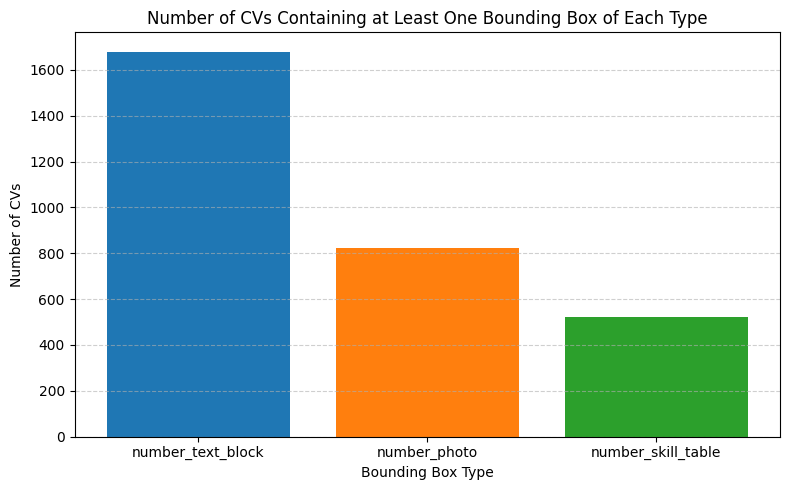

In [18]:
cols = ["number_text_block", "number_photo", "number_skill_table"]

# Count how many CVs contain at least one occurrence of each type
cvs_with_element = (df_yolo[cols] >= 1).sum()

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(
    cvs_with_element.index,
    cvs_with_element.values,
    color=["tab:blue", "tab:orange", "tab:green"]
)

plt.title("Number of CVs Containing at Least One Bounding Box of Each Type")
plt.ylabel("Number of CVs")
plt.xlabel("Bounding Box Type")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()



(array([  1.,   3.,  12.,  67., 169., 246., 321., 275., 231., 163.,  82.,
         63.,  28.,  13.,   4.,   1.,   0.,   0.,   0.,   1.]),
 array([ 1.  ,  1.95,  2.9 ,  3.85,  4.8 ,  5.75,  6.7 ,  7.65,  8.6 ,
         9.55, 10.5 , 11.45, 12.4 , 13.35, 14.3 , 15.25, 16.2 , 17.15,
        18.1 , 19.05, 20.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: number_text_block')

Text(0.5, 0, 'Number of Occurrences per CV')

Text(0, 0.5, 'Frequency')

(array([856.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 820.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   4.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
        1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([1.166e+03, 3.000e+01, 1.660e+02, 3.300e+01, 8.300e+01, 8.700e+01,
        4.200e+01, 2.500e+01, 3.400e+01, 5.000e+00, 2.000e+00, 3.000e+00,
        1.000e+00, 2.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.  ,  1.35,  2.7 ,  4.05,  5.4 ,  6.75,  8.1 ,  9.45, 10.8 ,
        12.15, 13.5 , 14.85, 16.2 , 17.55, 18.9 , 20.25, 21.6 , 22.95,
        24.3 , 25.65, 27.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: number_skill_table')

Text(0.5, 0, 'Number of Occurrences per CV')

Text(0, 0.5, 'Frequency')

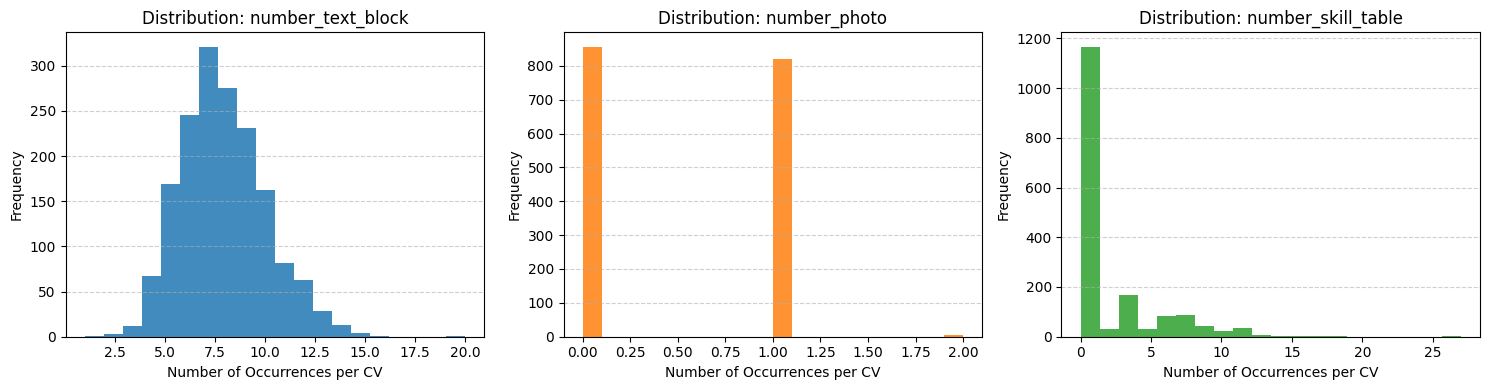

In [19]:
cols = [
    ("number_text_block", "tab:blue"),
    ("number_photo", "tab:orange"),
    ("number_skill_table", "tab:green"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.85)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel("Number of Occurrences per CV")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


<Figure size 700x500 with 0 Axes>

C:\Users\danie\AppData\Local\Temp\ipykernel_5088\3160410504.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


([<matplotlib.axis.YTick at 0x186bce425d0>,
 [Text(0, 0, '0'),
  Text(0, 2, '2'),
  Text(0, 4, '4'),
  Text(0, 6, '6'),
  Text(0, 8, '8'),
  Text(0, 10, '10'),
  Text(0, 12, '12'),
  Text(0, 14, '14'),
  Text(0, 16, '16'),
  Text(0, 18, '18'),
  Text(0, 20, '20'),
  Text(0, 22, '22'),
  Text(0, 24, '24'),
  Text(0, 26, '26'),
  Text(0, 28, '28')])

Text(0, 0.5, 'Number of Occurrences per CV')

Text(0.5, 1.0, 'Distribution of Bounding Boxes by Type')

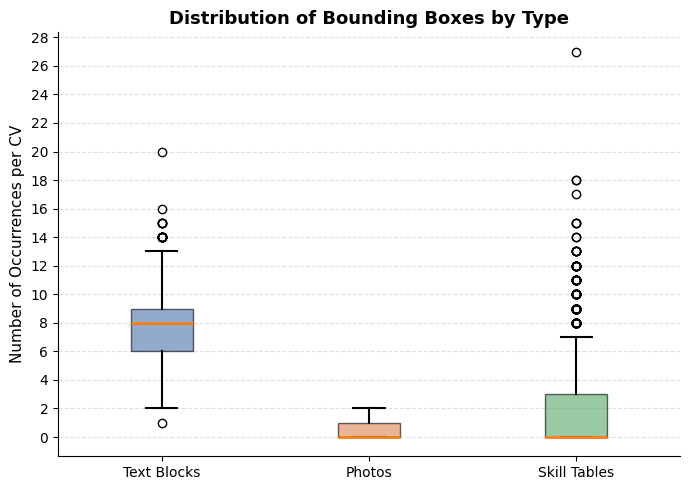

In [20]:
cols = ["number_text_block", "number_photo", "number_skill_table"]
data = [df_yolo[c] for c in cols]

plt.figure(figsize=(7, 5))

box = plt.boxplot(
    data,
    labels=["Text Blocks", "Photos", "Skill Tables"],
    patch_artist=True,
    showfliers=True,
    medianprops=dict(linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
)

# Cores suaves
colors = ["#4C72B0", "#DD8452", "#55A868"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

# ===== eixo Y com valores inteiros =====
y_max = int(max(df_yolo[cols].max()))
plt.yticks(np.arange(0, y_max + 2, 2))

# Estética geral
plt.ylabel("Number of Occurrences per CV", fontsize=11)
plt.title("Distribution of Bounding Boxes by Type", fontsize=13, weight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



#### 1.2.3 Correlation Matrix Numeric Values

In [30]:
def plot_numeric_correlations(
    df,
    cols=None,
    figsize=(6, 5),
    cmap="Blues",
    annot=True,
    vmin=-1,
    vmax=1,
    title="Correlation Matrix of Numeric Variables"
):
    """
    Plots a correlation heatmap for numeric variables in a DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataframe.
    cols : list[str] or None, optional
        List of columns to include. If None, all numeric columns are used.
    figsize : tuple, optional
        Figure size.
    cmap : str, optional
        Colormap for heatmap.
    annot : bool, optional
        Whether to display correlation values.
    vmin, vmax : float, optional
        Color scale limits.
    title : str, optional
        Plot title.
    """

    # Selecionar apenas colunas numéricas se não forem fornecidas
    if cols is None:
        data = df.select_dtypes(include="number")
    else:
        data = df[cols]

    # Calcular correlação
    corr = data.corr()

    # Criar figura
    plt.figure(figsize=figsize)
    sns.heatmap(
        corr,
        annot=annot,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8}
    )

    plt.title(title, fontsize=12, weight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()



def plot_yolo_numeric_correlations_final(
    df_yolo,
    numeric_cols_yolo,
    figsize=(12, 10),
    corr_threshold=0.98,
    cmap="vlag",
    annot=True,
    fmt=".2f",
    title="Correlation Structure of YOLO Numeric Features"
):
    """
    Publication-ready correlation heatmap for YOLO numeric features.

    Features:
    - removes near-duplicate variables
    - lower-triangle display
    - numeric annotations inside cells
    - larger, readable layout
    """

    # --- selecionar dados numéricos ---
    data = df_yolo[numeric_cols_yolo].select_dtypes(include="number")

    # --- remover variáveis quase duplicadas ---
    corr_full = data.corr().abs()
    upper = corr_full.where(np.triu(np.ones(corr_full.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > corr_threshold)]
    data = data.drop(columns=to_drop)

    # --- nova correlação ---
    corr = data.corr()

    # --- máscara metade superior ---
    mask = np.triu(np.ones_like(corr, dtype=bool))

    # --- plot ---
    plt.figure(figsize=figsize)

    sns.heatmap(
        corr,
        mask=mask,
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        annot=annot,
        fmt=fmt,
        annot_kws={"size": 8},
        cbar_kws={"shrink": 0.8, "label": "Pearson Correlation"}
    )

    plt.title(title, fontsize=15, weight="bold")
    plt.xticks(rotation=40, ha="right", fontsize=10)
    plt.yticks(rotation=0, fontsize=10)

    plt.tight_layout()
    plt.show()



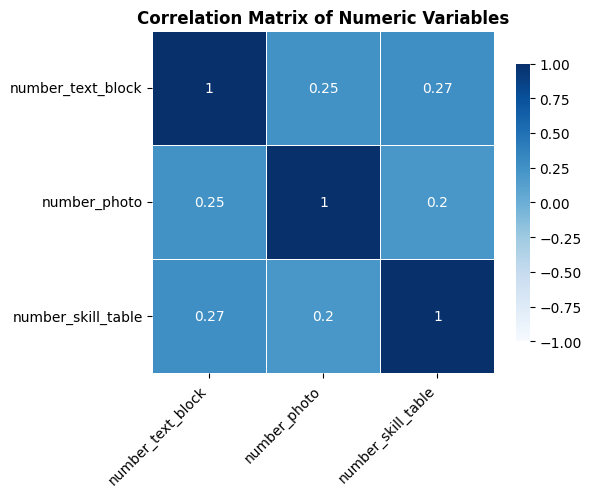

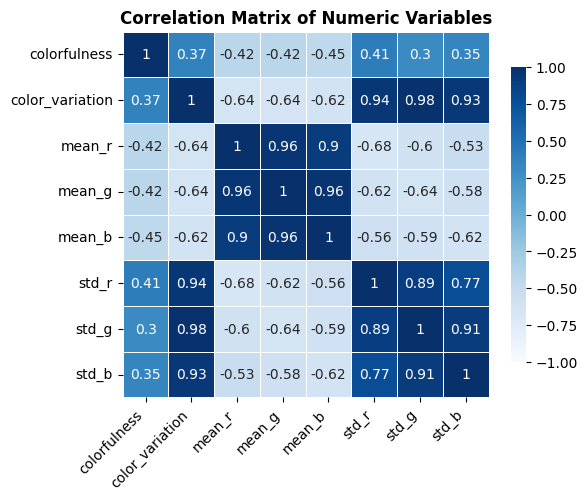

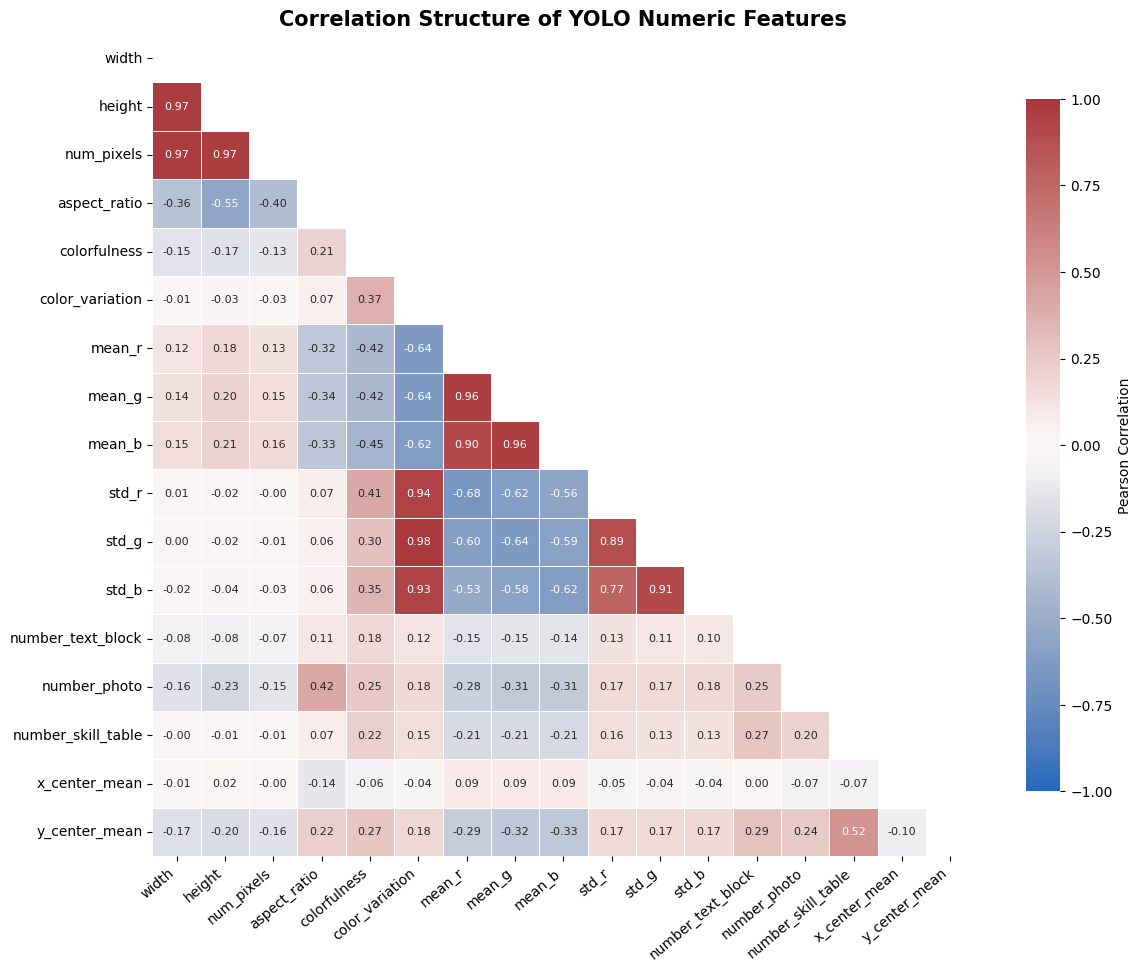

In [33]:
cols = ["number_text_block", "number_photo", "number_skill_table"]
color_cols = [
    "colorfulness", "color_variation",
    "mean_r", "mean_g", "mean_b",
    "std_r", "std_g", "std_b"
]
plot_numeric_correlations(df_yolo, cols)

plot_numeric_correlations(df_yolo, color_cols)


plot_yolo_numeric_correlations_final(df_yolo, numeric_cols_yolo)





#### 1.2.4 Graphs of the colors

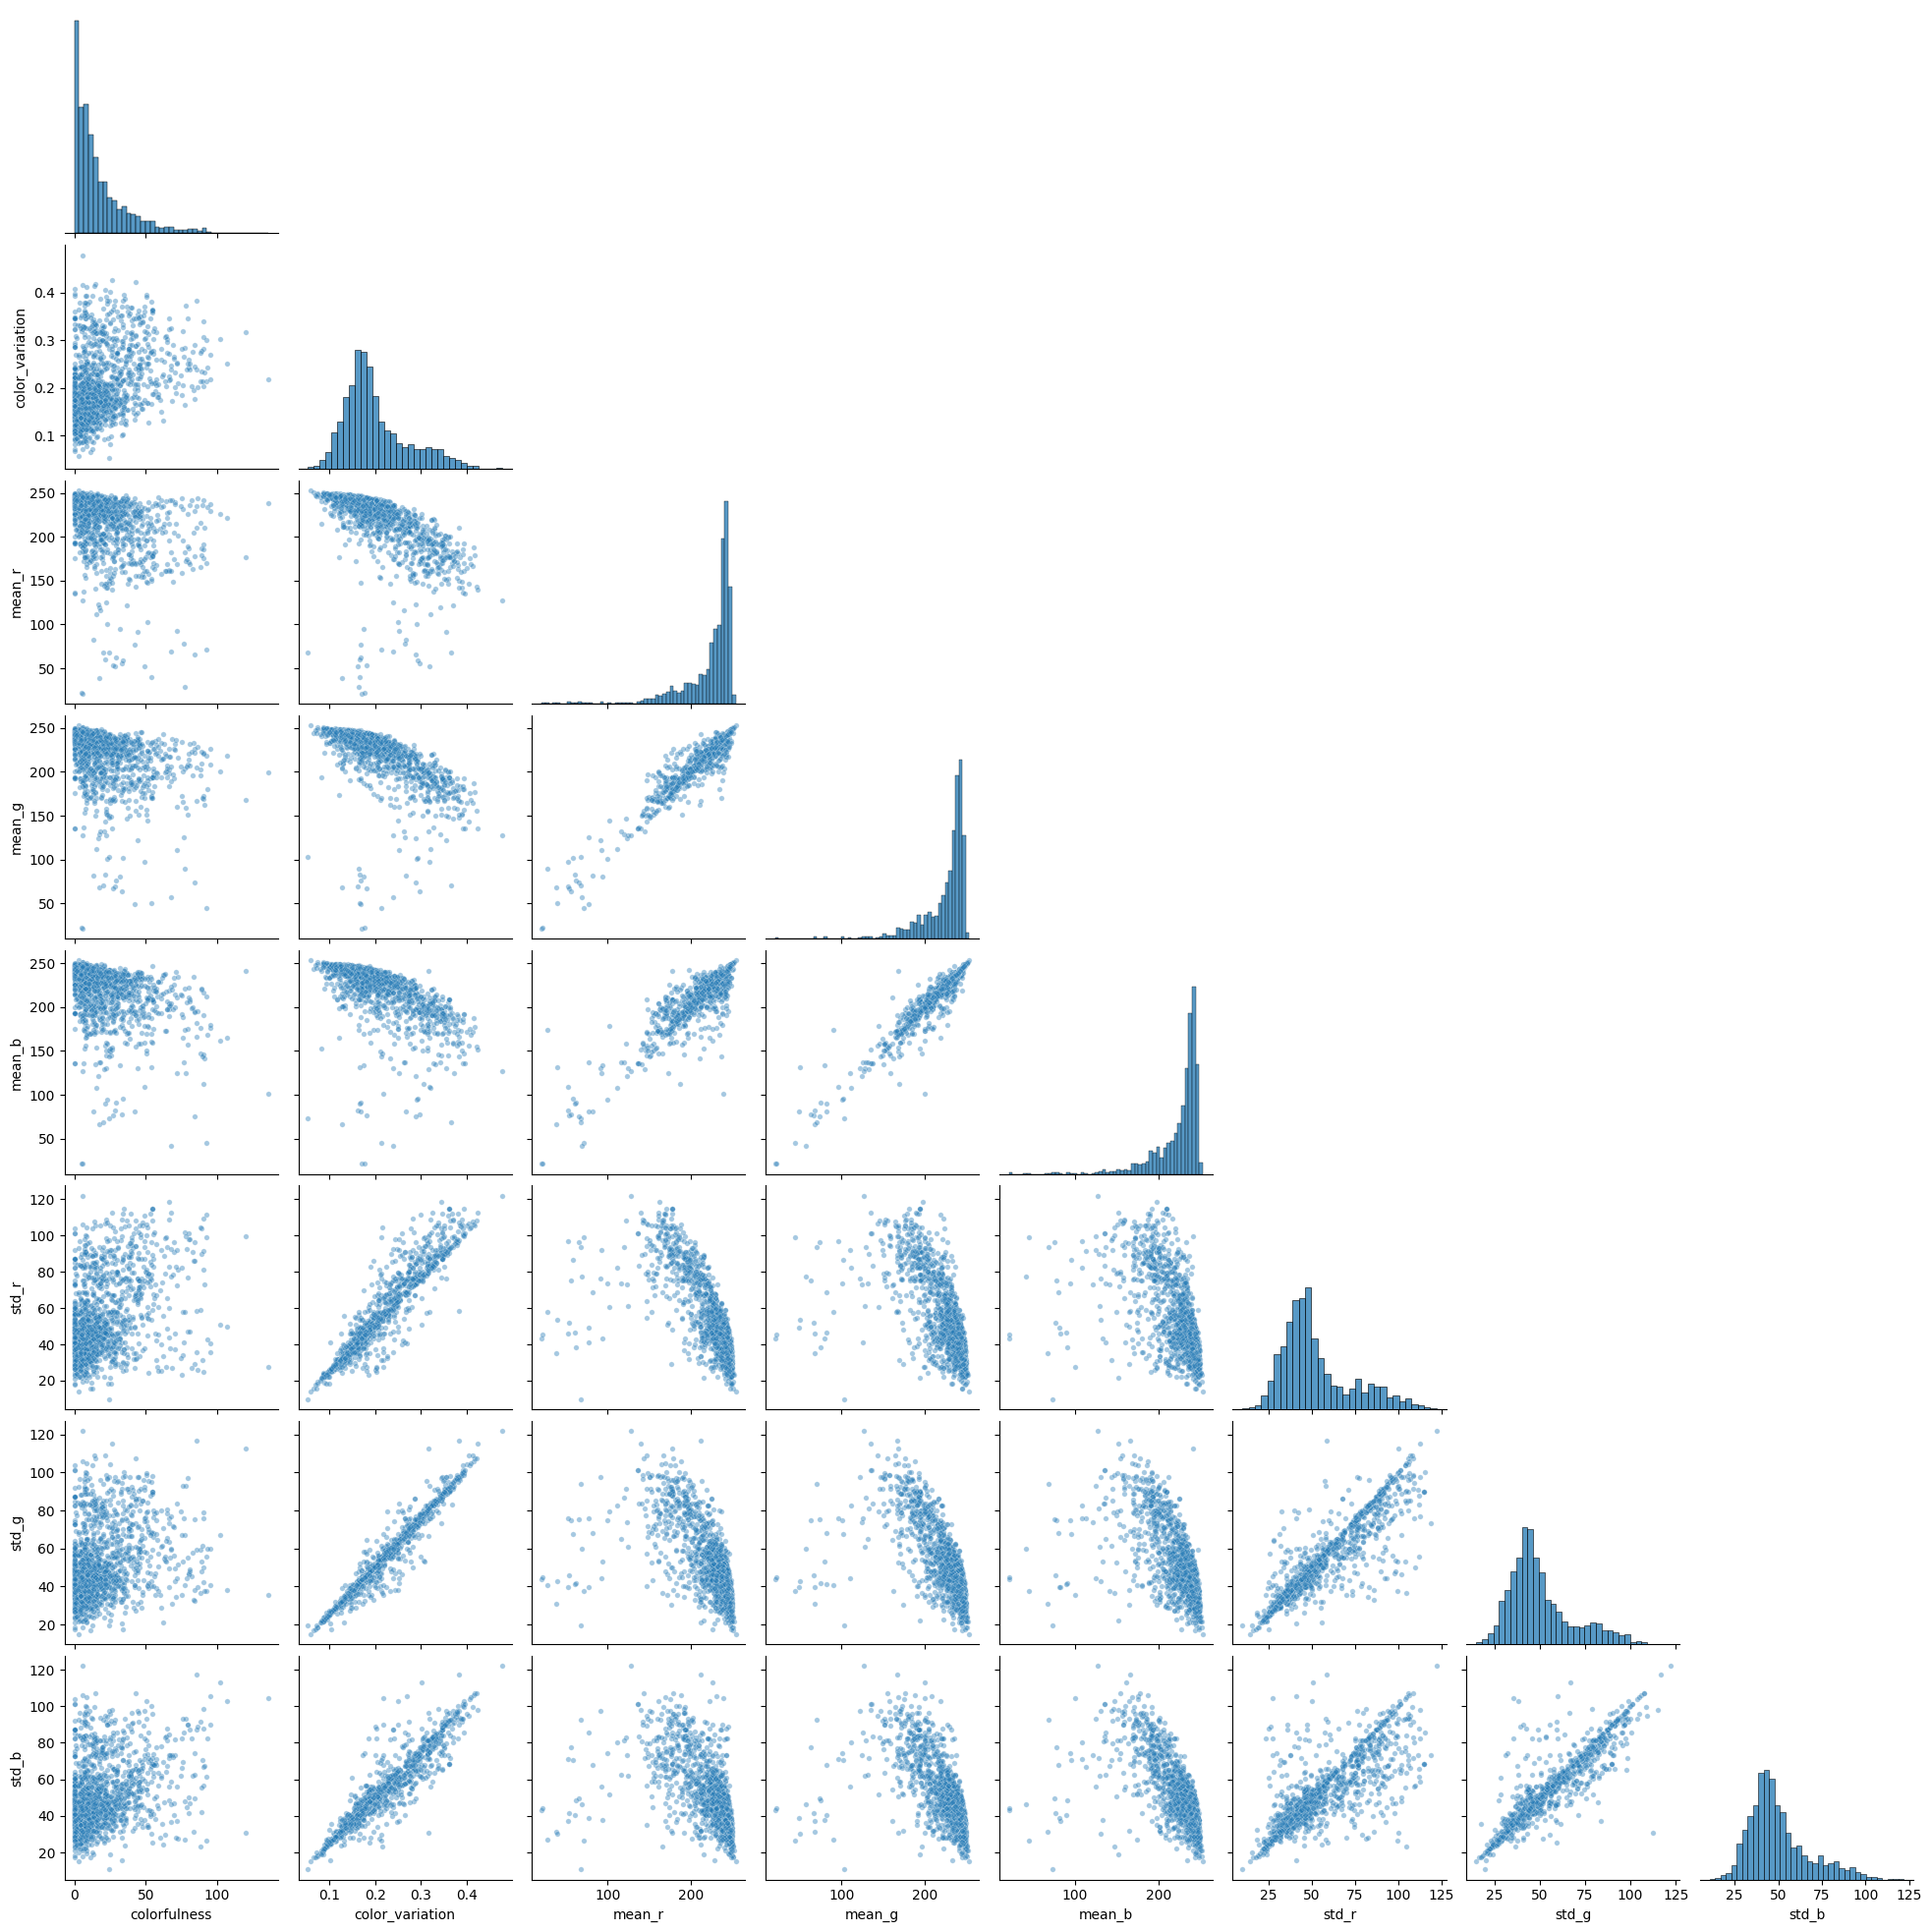

In [32]:
color_cols = [
    "colorfulness", "color_variation",
    "mean_r", "mean_g", "mean_b",
    "std_r", "std_g", "std_b"
]

sns.pairplot(df_yolo[color_cols], corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.show()


<Axes: xlabel='colorfulness', ylabel='number_skill_table'>

Text(0.5, 1.0, 'Colorfulness vs Number of Skill Tables')

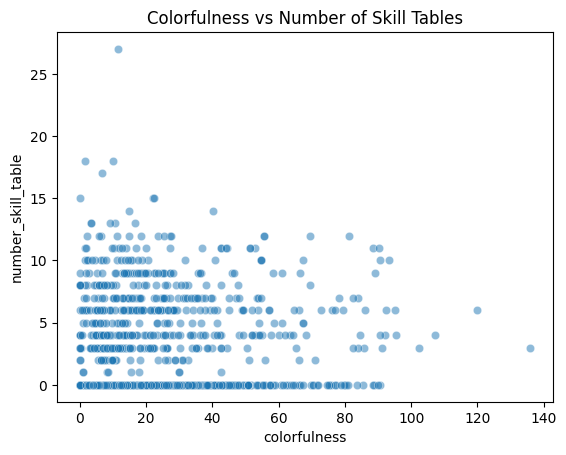

In [34]:
sns.scatterplot(
    data=df_yolo,
    x="colorfulness",
    y="number_skill_table",
    alpha=0.5
)
plt.title("Colorfulness vs Number of Skill Tables")
plt.show()


<Axes: xlabel='has_photo', ylabel='colorfulness'>

Text(0.5, 1.0, 'Colorfulness Distribution by Photo Presence')

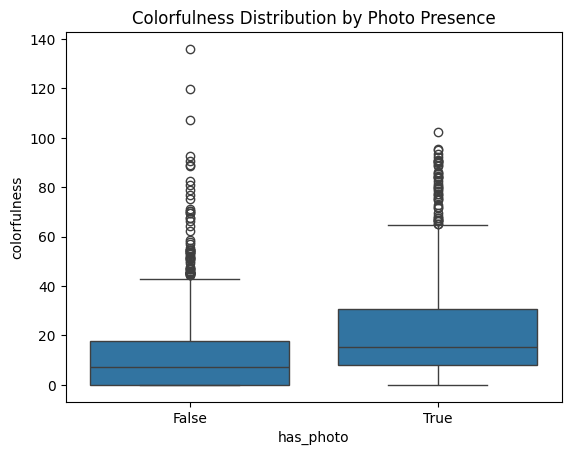

In [35]:
import seaborn as sns

df_yolo["has_photo"] = df_yolo["number_photo"] > 0

sns.boxplot(data=df_yolo, x="has_photo", y="colorfulness")
plt.title("Colorfulness Distribution by Photo Presence")
plt.show()


(array([  3.,   2.,   4.,   4.,   6.,   1.,   5.,   1.,   5.,   3.,  16.,
         24.,  44.,  63.,  64.,  88., 117., 241., 562., 427.]),
 array([ 21.108418 ,  32.7094461,  44.3104742,  55.9115023,  67.5125304,
         79.1135585,  90.7145866, 102.3156147, 113.9166428, 125.5176709,
        137.118699 , 148.7197271, 160.3207552, 171.9217833, 183.5228114,
        195.1238395, 206.7248676, 218.3258957, 229.9269238, 241.5279519,
        253.12898  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: mean_r')

Text(0.5, 0, 'Mean Intensity Value')

Text(0, 0.5, 'Frequency')

(array([  2.,   0.,   3.,   3.,   5.,   4.,   3.,   3.,   2.,  10.,   4.,
         18.,  36.,  45.,  88., 100., 109., 237., 584., 424.]),
 array([ 20.914013  ,  32.51867935,  44.1233457 ,  55.72801205,
         67.3326784 ,  78.93734475,  90.5420111 , 102.14667745,
        113.7513438 , 125.35601015, 136.9606765 , 148.56534285,
        160.1700092 , 171.77467555, 183.3793419 , 194.98400825,
        206.5886746 , 218.19334095, 229.7980073 , 241.40267365,
        253.00734   ]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([  2.,   1.,   1.,   1.,   5.,   4.,   4.,   3.,   3.,  12.,   9.,
         22.,  27.,  43.,  81., 102., 128., 232., 574., 426.]),
 array([ 21.450272 ,  33.0262019,  44.6021318,  56.1780617,  67.7539916,
         79.3299215,  90.9058514, 102.4817813, 114.0577112, 125.6336411,
        137.209571 , 148.7855009, 160.3614308, 171.9373607, 183.5132906,
        195.0892205, 206.6651504, 218.2410803, 229.8170102, 241.3929401,
        252.96887  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: mean_b')

Text(0.5, 0, 'Mean Intensity Value')

Text(0, 0.5, 'Frequency')

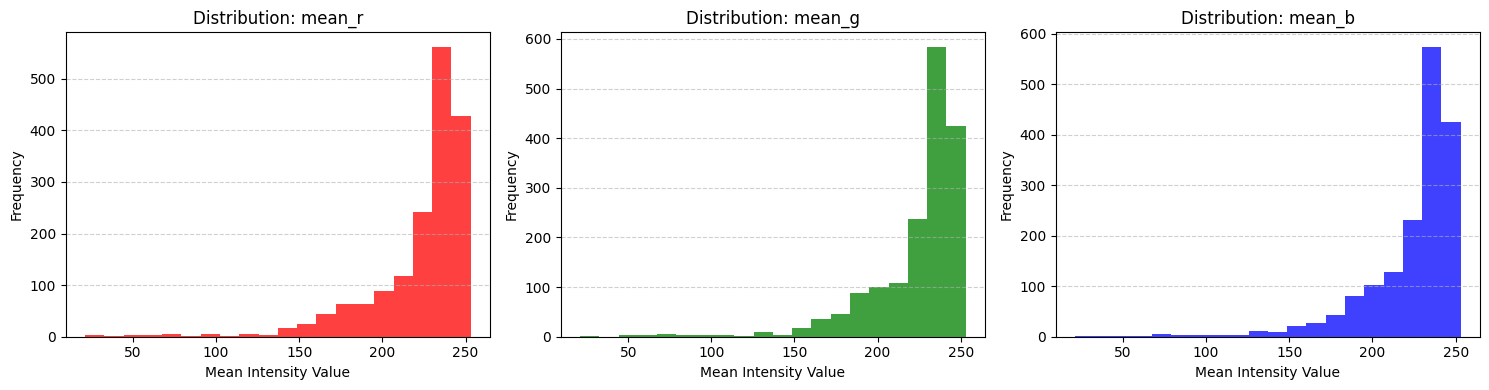

In [36]:
cols = [
    ("mean_r", "red"),
    ("mean_g", "green"),
    ("mean_b", "blue"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.75)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel("Mean Intensity Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


(array([  2.,  10.,  46., 135., 203., 267., 301., 191.,  97.,  61.,  43.,
         73.,  50.,  56.,  56.,  32.,  25.,  19.,  11.,   2.]),
 array([  9.817783 ,  15.4264006,  21.0350182,  26.6436358,  32.2522534,
         37.860871 ,  43.4694886,  49.0781062,  54.6867238,  60.2953414,
         65.903959 ,  71.5125766,  77.1211942,  82.7298118,  88.3384294,
         93.947047 ,  99.5556646, 105.1642822, 110.7728998, 116.3815174,
        121.990135 ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: std_r')

Text(0.5, 0, 'Standard Deviation of Intensity')

Text(0, 0.5, 'Frequency')

(array([  8.,  31., 100., 188., 259., 322., 220., 131.,  89.,  56.,  54.,
         54.,  56.,  41.,  28.,  28.,   6.,   5.,   2.,   2.]),
 array([ 14.853164 ,  20.2070018,  25.5608396,  30.9146774,  36.2685152,
         41.622353 ,  46.9761908,  52.3300286,  57.6838664,  63.0377042,
         68.391542 ,  73.7453798,  79.0992176,  84.4530554,  89.8068932,
         95.160731 , 100.5145688, 105.8684066, 111.2222444, 116.5760822,
        121.92992  ]),
 <BarContainer object of 20 artists>)

...

Text(0, 0.5, 'Frequency')

(array([  3.,  12.,  47., 137., 219., 323., 291., 180., 114.,  84.,  55.,
         57.,  55.,  35.,  33.,  18.,  10.,   4.,   1.,   2.]),
 array([ 10.739143  ,  16.29679185,  21.8544407 ,  27.41208955,
         32.9697384 ,  38.52738725,  44.0850361 ,  49.64268495,
         55.2003338 ,  60.75798265,  66.3156315 ,  71.87328035,
         77.4309292 ,  82.98857805,  88.5462269 ,  94.10387575,
         99.6615246 , 105.21917345, 110.7768223 , 116.33447115,
        121.89212   ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribution: std_b')

Text(0.5, 0, 'Standard Deviation of Intensity')

Text(0, 0.5, 'Frequency')

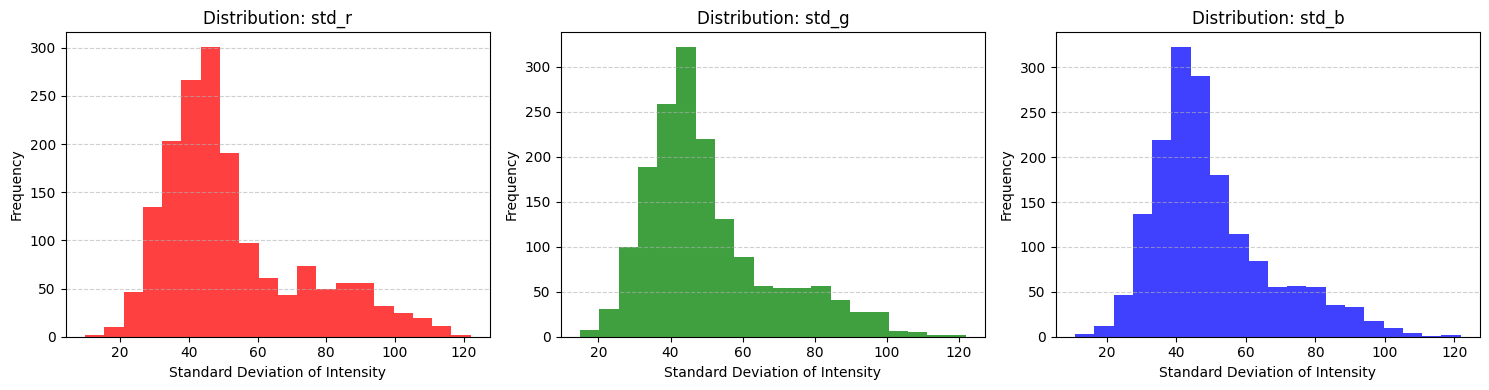

In [37]:
cols = [
    ("std_r", "red"),
    ("std_g", "green"),
    ("std_b", "blue"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=20, color=color, alpha=0.75)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel("Standard Deviation of Intensity")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


(array([486., 351., 229., 143., 104.,  78.,  63.,  49.,  42.,  34.,  23.,
         15.,  15.,   8.,  12.,   9.,  12.,   3.,   1.,   1.,   0.,   0.,
          1.,   0.,   1.]),
 array([  0.        ,   5.43990662,  10.87981323,  16.31971985,
         21.75962646,  27.19953308,  32.6394397 ,  38.07934631,
         43.51925293,  48.95915955,  54.39906616,  59.83897278,
         65.27887939,  70.71878601,  76.15869263,  81.59859924,
         87.03850586,  92.47841248,  97.91831909, 103.35822571,
        108.79813232, 114.23803894, 119.67794556, 125.11785217,
        130.55775879, 135.99766541]),
 <BarContainer object of 25 artists>)

Text(0.5, 1.0, 'Distribution: colorfulness')

Text(0.5, 0, 'Value')

Text(0, 0.5, 'Frequency')

(array([  4.,   9.,  34.,  79., 134., 172., 259., 248., 167., 113.,  75.,
         73.,  43.,  56.,  42.,  44.,  34.,  39.,  23.,  18.,   7.,   6.,
          0.,   0.,   1.]),
 array([0.05245991, 0.06948938, 0.08651886, 0.10354834, 0.12057782,
        0.1376073 , 0.15463678, 0.17166625, 0.18869573, 0.20572521,
        0.22275469, 0.23978417, 0.25681364, 0.27384312, 0.2908726 ,
        0.30790208, 0.32493156, 0.34196103, 0.35899051, 0.37601999,
        0.39304947, 0.41007895, 0.42710843, 0.4441379 , 0.46116738,
        0.47819686]),
 <BarContainer object of 25 artists>)

Text(0.5, 1.0, 'Distribution: color_variation')

Text(0.5, 0, 'Value')

Text(0, 0.5, 'Frequency')

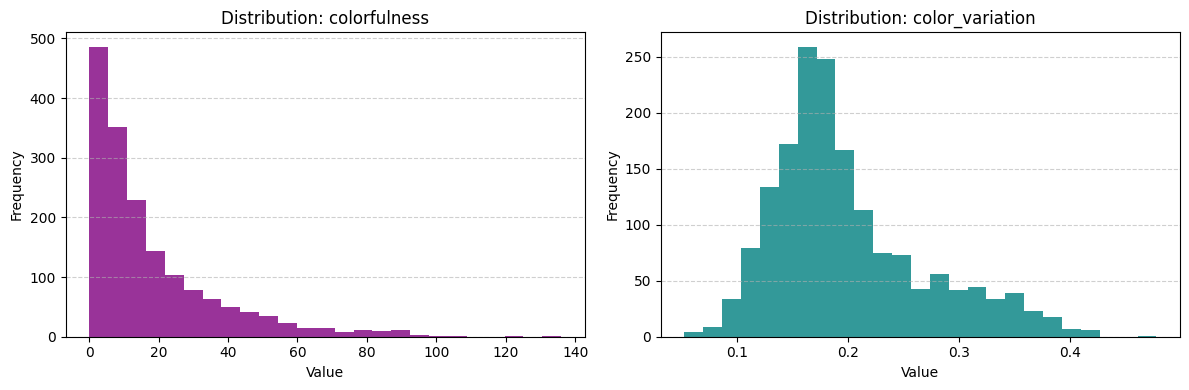

In [38]:
import matplotlib.pyplot as plt

cols = [
    ("colorfulness", "purple"),
    ("color_variation", "teal"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (col, color) in zip(axes, cols):
    ax.hist(df_yolo[col], bins=25, color=color, alpha=0.8)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# Color-Based Feature Analysis

## 1. Colorfulness

**Colorfulness** is a perceptual metric commonly used in computer vision to quantify the intensity of colors in an image.
It is based on the opponent color components derived from RGB channels:


rg = R - G


yb = (R + G)/2 - B


From these components, the standard deviations and means are computed:


std_rg, std_yb, std_rg, std_yb


The final colorfulness measure is defined as:

[
\text{colorfulness} =
\sqrt{\sigma_{rg}^2 + \sigma_{yb}^2}
;+;
0.3 \cdot \sqrt{\mu_{rg}^2 + \mu_{yb}^2}
]

### Interpretation

* **Low values** indicate nearly monochromatic images
  (e.g., black text on white background, typical of simple CV layouts).

* **High values** suggest the presence of:

  * graphics or charts
  * colored design elements
  * photographs

### Observed Distribution

The histogram shows a **strong right-skewed distribution**:

* Most CVs concentrate at **low colorfulness values (≈ 0–20)**.
* A small subset extends to **very high values (>100)**.

This indicates that:

> The dataset is dominated by visually simple, mostly monochromatic CVs,
> with relatively few highly colorful layouts.

---

## 2. Color Variation

**Color variation** measures the overall dispersion of color intensities across RGB channels.
It is typically computed as the average standard deviation of the three channels:

[
\text{color variation} =
\frac{1}{3} \left( \sigma_R + \sigma_G + \sigma_B \right)
]

This metric captures **how heterogeneous the color distribution** is within the image.

### Interpretation

* **Low values** → uniform or weakly varying colors
* **High values** → strong visual heterogeneity, often caused by:

  * images or photographs
  * multicolored graphics
  * complex visual layouts

### Observed Distribution

The distribution is **approximately unimodal with moderate right skew**:

* Peak around **0.15–0.22**
* Gradual tail extending toward **≈ 0.4**

This suggests that:

> Even simple CVs exhibit some degree of color variation
> (e.g., headings, icons, or subtle formatting),
> while only a small fraction contains strongly heterogeneous visual content.

---

## 3. Implications for CV Visual Analysis

These findings provide important insights for the document-analysis pipeline:

1. **Dataset Visual Simplicity**
   Most CVs are largely monochromatic, implying that:

   * text-based features dominate
   * highly graphical layouts are underrepresented.

2. **Discriminative Power of Colorfulness**
   Colorfulness can help identify CVs containing:

   * skill charts
   * photographs
   * modern visual templates.

3. **Complementarity of Color Variation**

   * *Colorfulness* captures **chromatic intensity**.
   * *Color variation* captures **spatial dispersion of color**.

Together, they provide a **robust visual characterization** useful for:

* layout analysis
* CV quality ranking
* filtering or clustering document styles

